# 12 - Model Comparison (Experiment 1)

**Project:** DetectIt – Intelligent Web Threat Detection Using Machine Learning

**Goal:** Compare all 8 models from Experiment 1 on the same PhiUSIIL test set and choose the best model.

**Input:** `results/metrics/` (one results table for each model)

**Output:** `results/comparison/`

## Setup

Every model notebook saved its results in `results/metrics/` with the same shared functions. So all scores here were calculated in the same way, on the same test set, and can be compared fairly.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append(str(Path("..").resolve()))
from src.data import PROCESSED_DIR, TARGET
from src.evaluation import RESULTS_DIR

METRICS_DIR = RESULTS_DIR / "metrics"
SAVE_DIR = RESULTS_DIR / "comparison"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

MODELS = {
    "xgboost": "Supervised",
    "random_forest": "Supervised",
    "decision_tree": "Supervised",
    "logistic_regression": "Supervised",
    "knn": "Supervised",
    "svm": "Supervised",
    "naive_bayes": "Supervised",
    "isolation_forest": "Unsupervised",
}

METRIC_COLS = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
COLOR = "#4C72B0"

## 1. Load the Results

We load the results table of each model and join them into one table. We also count the test URLs, so we can turn accuracy into the number of mistakes. With scores this close to 100%, the number of mistakes is much easier to compare.

In [2]:
all_results = pd.concat(
    [pd.read_csv(METRICS_DIR / f"{name}.csv").assign(Type=model_type) for name, model_type in MODELS.items()],
    ignore_index=True,
)

test_size = len(pd.read_csv(PROCESSED_DIR / "test.csv", usecols=[TARGET]))
all_results["Mistakes"] = ((1 - all_results["Accuracy"]) * test_size).round().astype(int)

print(f"Models: {all_results['Model'].nunique()}")
print(f"Test URLs: {test_size:,}")

Models: 8
Test URLs: 46,841


## 2. Test Set Results

This is the main comparison. Every model was trained on the full training set with its best settings and tested once on the same test set, using all 69 features. The table is sorted by F1-score.

In [3]:
test_table = (
    all_results[all_results["Experiment"] == "Test set - All features"]
    .set_index("Model")[["Type", *METRIC_COLS, "Mistakes", "Train Time (s)"]]
    .sort_values(["F1", "Mistakes"], ascending=[False, True])
)
test_table.round(4)

,Type,Accuracy,Precision,Recall,F1,ROC-AUC,Mistakes,Train Time (s)
Model,,,,,,,,
Random Forest,Supervised,1.0000,1.0000,1.0000,1.0000,1.0000,0,5.9476
Decision Tree,Supervised,1.0000,1.0000,1.0000,1.0000,1.0000,0,0.6009
XGBoost,Supervised,1.0000,1.0000,0.9999,0.9999,1.0000,2,2.6543
Logistic Regression,Supervised,1.0000,1.0000,0.9999,0.9999,1.0000,2,0.4741
SVM,Supervised,1.0000,1.0000,0.9999,0.9999,1.0000,2,1.5050
Naive Bayes,Supervised,0.9997,0.9994,0.9999,0.9996,0.9998,14,0.3206
KNN,Supervised,0.9992,0.9997,0.9983,0.9990,0.9998,39,0.2880
Isolation Forest,Unsupervised,0.8968,0.8688,0.8914,0.8800,0.9568,4832,0.8502


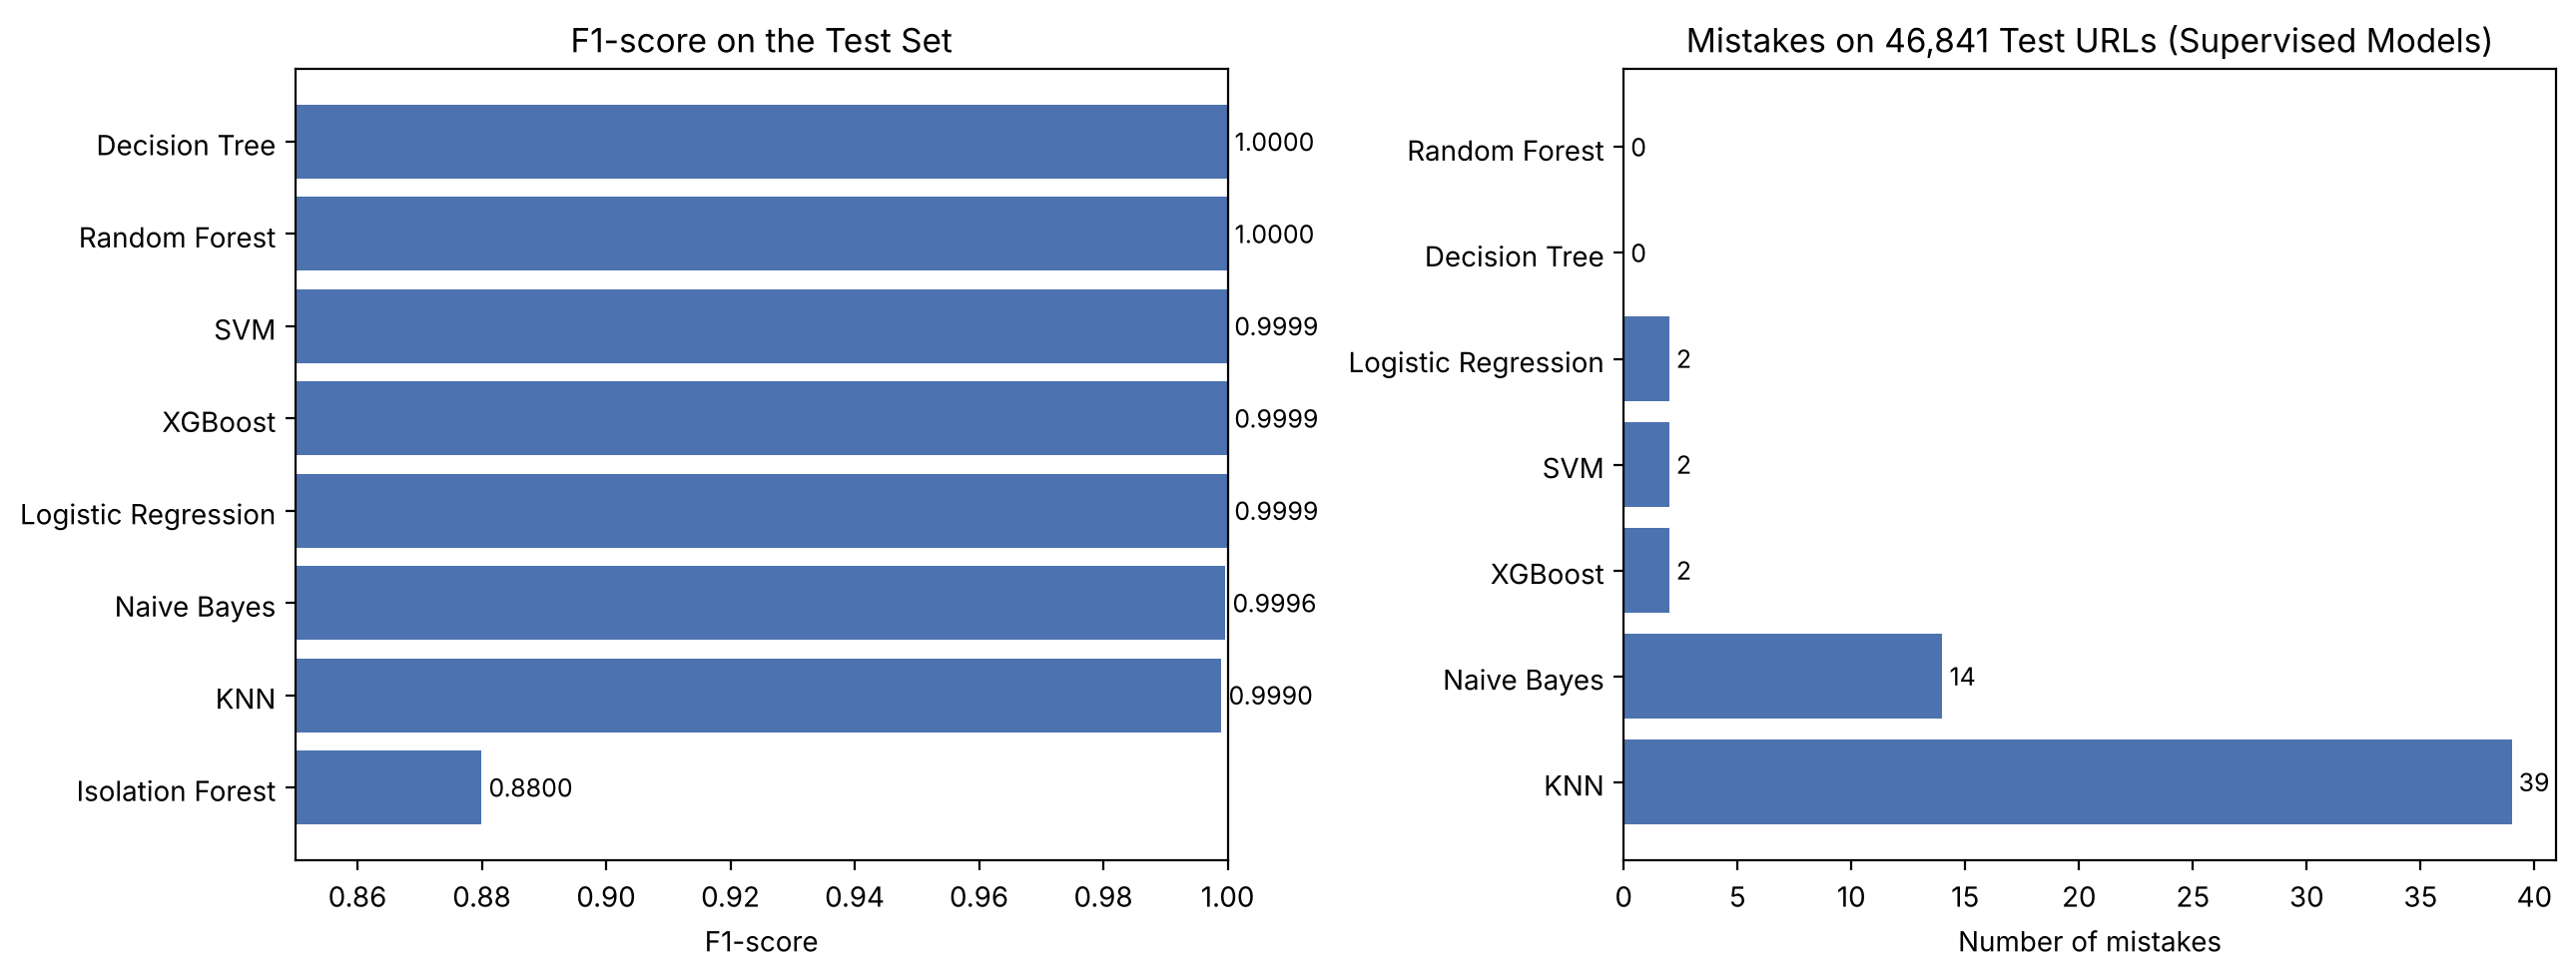

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

f1 = test_table["F1"].sort_values()
axes[0].barh(f1.index, f1.values, color=COLOR)
axes[0].set_xlim(0.85, 1.0)
axes[0].set_title("F1-score on the Test Set")
axes[0].set_xlabel("F1-score")
for i, v in enumerate(f1.values):
    axes[0].text(v, i, f" {v:.4f}", va="center", fontsize=9)

supervised = test_table[test_table["Type"] == "Supervised"]["Mistakes"].sort_values(ascending=False)
axes[1].barh(supervised.index, supervised.values, color=COLOR)
axes[1].set_title(f"Mistakes on {test_size:,} Test URLs (Supervised Models)")
axes[1].set_xlabel("Number of mistakes")
for i, v in enumerate(supervised.values):
    axes[1].text(v, i, f" {v}", va="center", fontsize=9)

fig.tight_layout()
fig.savefig(SAVE_DIR / "test_set_comparison.png", dpi=300)
plt.show()

Isolation Forest is left out of the mistakes chart because it made thousands of mistakes, which would hide the small differences between the other models.

## 3. Cross-Validation vs Test Set

If a model is much better in cross-validation than on the test set, it may be overfitting. Here we put the two F1-scores side by side.

In [5]:
cv_f1 = all_results[all_results["Experiment"] == "Cross-validation"].set_index("Model")["F1"]

overfit_table = pd.DataFrame({
    "Cross-validation F1": cv_f1,
    "Test F1": test_table["F1"],
})
overfit_table["Difference"] = (overfit_table["Cross-validation F1"] - overfit_table["Test F1"]).round(4).replace(-0.0, 0.0)
overfit_table.loc[test_table.index].round(4)

,Cross-validation F1,Test F1,Difference
Model,,,
Random Forest,1.0000,1.0000,0.0000
Decision Tree,1.0000,1.0000,0.0000
XGBoost,1.0000,0.9999,0.0000
Logistic Regression,0.9999,0.9999,-0.0001
SVM,0.9999,0.9999,-0.0001
Naive Bayes,0.9997,0.9996,0.0000
KNN,0.9979,0.9990,-0.0011
Isolation Forest,0.8804,0.8800,0.0004


## 4. Feature Set Comparison

Each model was also trained on two smaller feature sets:

- **Original features only:** shows if our new features from feature engineering helped.
- **Without `URLSimilarityIndex`:** shows if the model still works without its strongest feature.

We compare the number of mistakes on the test set.

In [6]:
feature_experiments = {
    "Test set - All features": "All features",
    "Test set - Original features only": "Original features only",
    "Test set - Without URLSimilarityIndex": "Without URLSimilarityIndex",
}

feature_table = (
    all_results[all_results["Experiment"].isin(feature_experiments)]
    .assign(Experiment=lambda df: df["Experiment"].map(feature_experiments))
    .pivot(index="Model", columns="Experiment", values="Mistakes")
    .loc[test_table.index, list(feature_experiments.values())]
)
feature_table

Experiment,All features,Original features only,Without URLSimilarityIndex
Model,,,
Random Forest,0,2,3
Decision Tree,0,0,258
XGBoost,2,2,6
Logistic Regression,2,2,2
SVM,2,2,2
Naive Bayes,14,23,203
KNN,39,28,41
Isolation Forest,4832,4817,4697


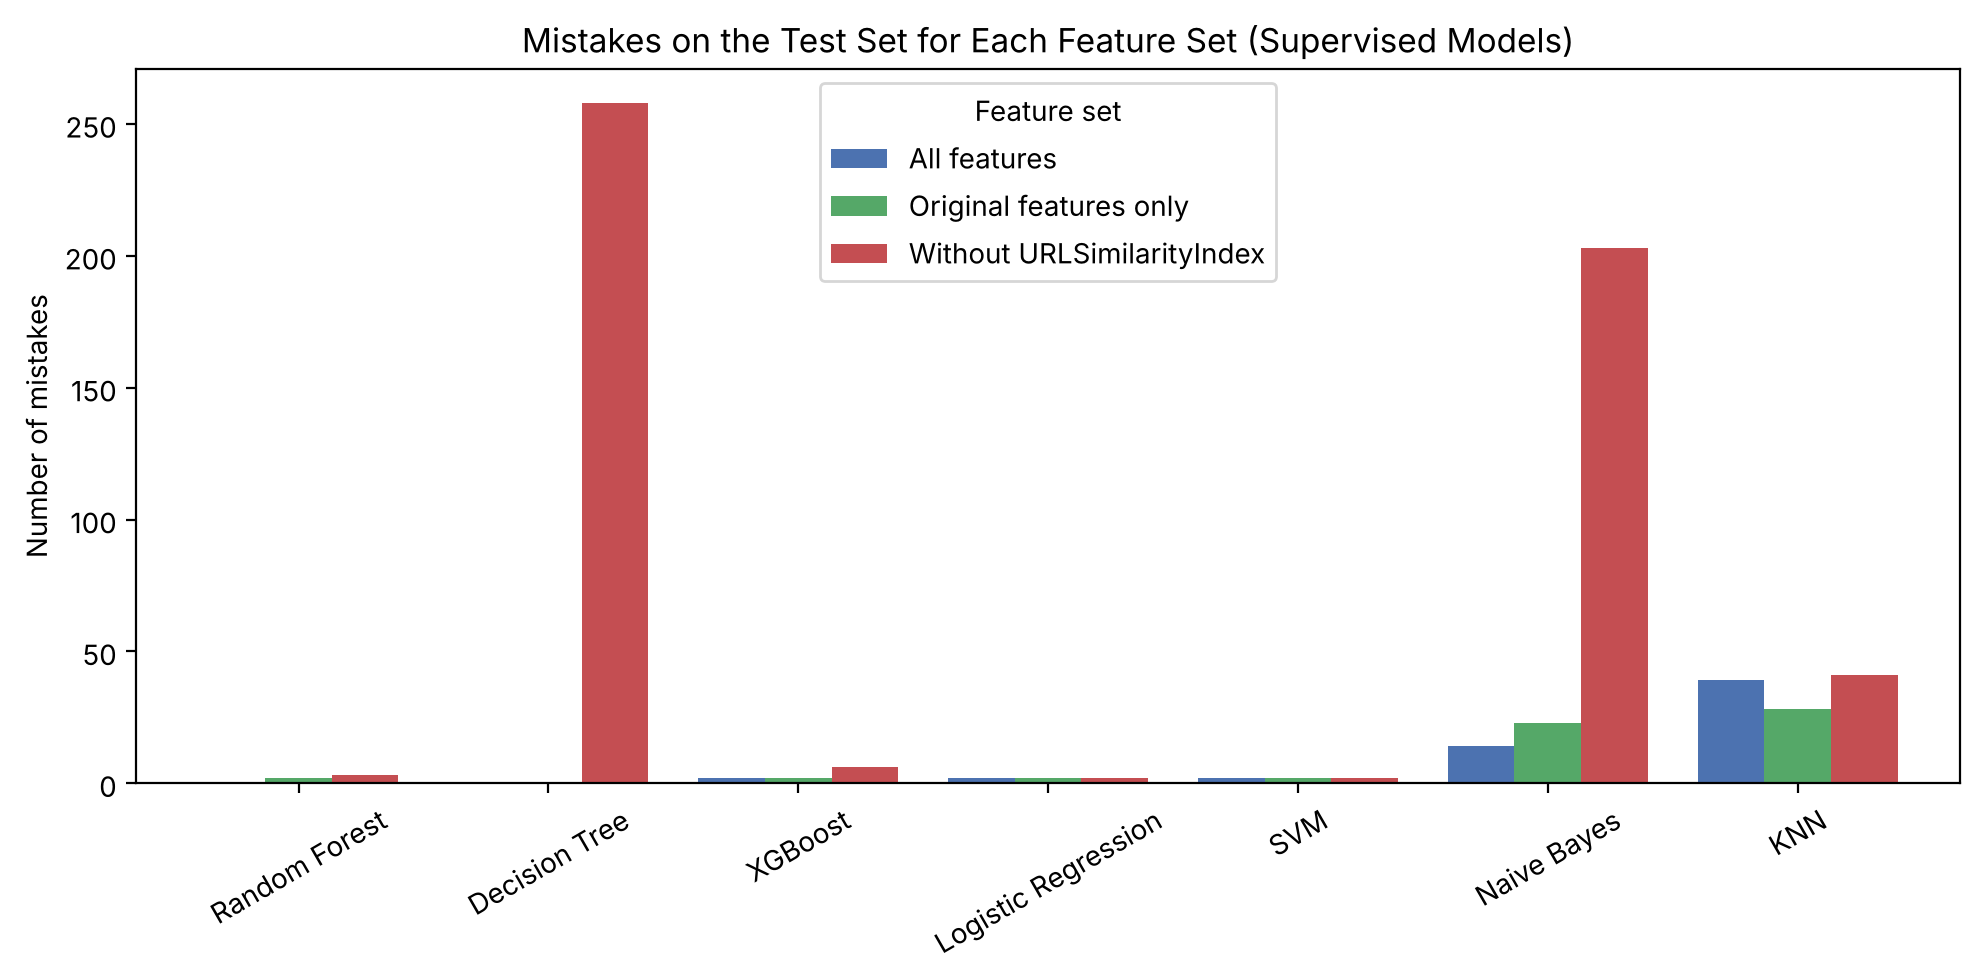

In [7]:
plot_table = feature_table.drop(index="Isolation Forest")

fig, ax = plt.subplots(figsize=(10, 5))
plot_table.plot.bar(ax=ax, color=["#4C72B0", "#55A868", "#C44E52"], width=0.8)
ax.set_title("Mistakes on the Test Set for Each Feature Set (Supervised Models)")
ax.set_ylabel("Number of mistakes")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=30)
ax.legend(title="Feature set")
fig.tight_layout()
fig.savefig(SAVE_DIR / "feature_set_comparison.png", dpi=300)
plt.show()

## 5. Training Time

A good model should also be fast to train, so it is easy to retrain when new phishing URLs appear.

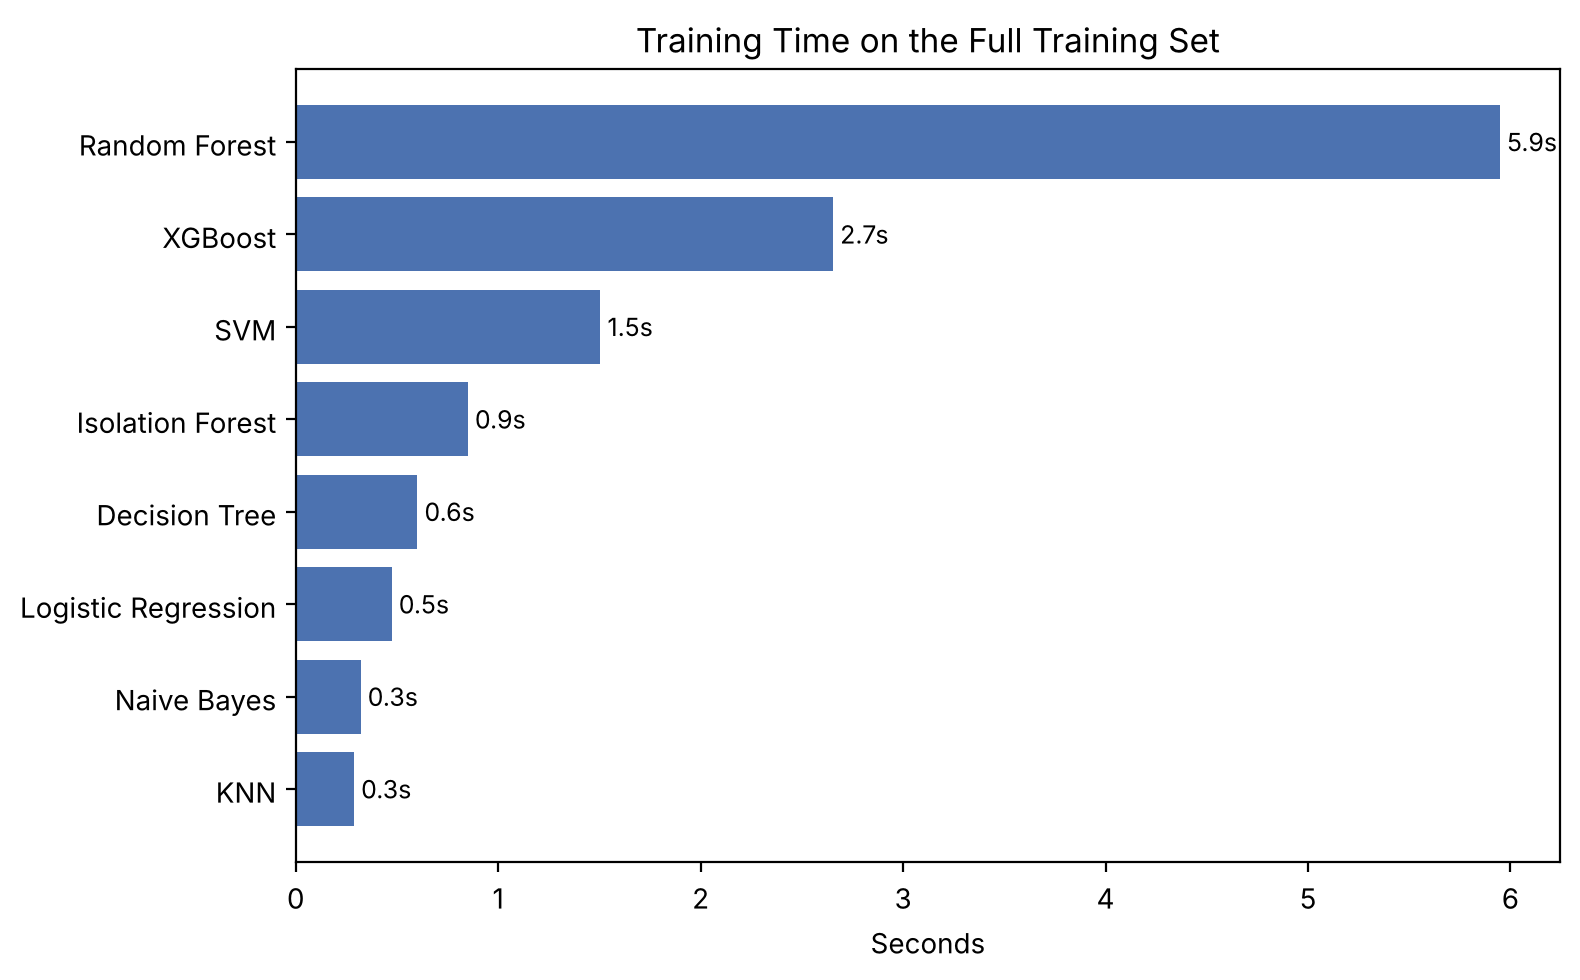

In [8]:
train_time = test_table["Train Time (s)"].sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(train_time.index, train_time.values, color=COLOR)
ax.set_title("Training Time on the Full Training Set")
ax.set_xlabel("Seconds")
for i, v in enumerate(train_time.values):
    ax.text(v, i, f" {v:.1f}s", va="center", fontsize=9)
fig.tight_layout()
fig.savefig(SAVE_DIR / "training_time.png", dpi=300)
plt.show()

## 6. Save the Comparison Table

We save one final table with the main results of every model. We will use this table in the report.

In [9]:
comparison = test_table.join(feature_table[["Without URLSimilarityIndex"]].rename(columns={"Without URLSimilarityIndex": "Mistakes Without URLSimilarityIndex"}))
comparison = comparison.join(overfit_table[["Cross-validation F1"]])
comparison.to_csv(SAVE_DIR / "model_comparison.csv")
comparison.round(4)

,Type,Accuracy,Precision,Recall,F1,ROC-AUC,Mistakes,Train Time (s),Mistakes Without URLSimilarityIndex,Cross-validation F1
Model,,,,,,,,,,
Random Forest,Supervised,1.0000,1.0000,1.0000,1.0000,1.0000,0,5.9476,3,1.0000
Decision Tree,Supervised,1.0000,1.0000,1.0000,1.0000,1.0000,0,0.6009,258,1.0000
XGBoost,Supervised,1.0000,1.0000,0.9999,0.9999,1.0000,2,2.6543,6,1.0000
Logistic Regression,Supervised,1.0000,1.0000,0.9999,0.9999,1.0000,2,0.4741,2,0.9999
SVM,Supervised,1.0000,1.0000,0.9999,0.9999,1.0000,2,1.5050,2,0.9999
Naive Bayes,Supervised,0.9997,0.9994,0.9999,0.9996,0.9998,14,0.3206,203,0.9997
KNN,Supervised,0.9992,0.9997,0.9983,0.9990,0.9998,39,0.2880,41,0.9979
Isolation Forest,Unsupervised,0.8968,0.8688,0.8914,0.8800,0.9568,4832,0.8502,4697,0.8804


## 7. Findings

- **All supervised models are almost perfect.** The 7 supervised models made between 0 and 39 mistakes on 46,841 test URLs (accuracy 99.92% or more). This shows that the PhiUSIIL features separate phishing and legitimate URLs very clearly.
- **Top models:** Random Forest and Decision Tree made 0 mistakes. XGBoost, Logistic Regression and SVM made 2 mistakes each, and they all missed the same 2 phishing URLs, which look like plain home pages. Naive Bayes (14) and KNN (39) were a little behind.
- **Isolation Forest is much weaker** (accuracy 89.7%, 4,832 mistakes). This is expected, because it is unsupervised. It never sees the labels during training and only learns what normal (legitimate) URLs look like.
- **No overfitting:** For every model the cross-validation F1 and the test F1 are almost the same (difference 0.0012 or less). So the models work as well on new URLs as on the training data.
- **New features:** Using only the original features gave almost the same results. On this dataset the original features are already strong, so feature engineering did not change Experiment 1 much. Naive Bayes (23 → 14 mistakes) and Random Forest (2 → 0) improved a little with our new features, while KNN did slightly better without them (28 vs 39).
- **Without `URLSimilarityIndex`:** Decision Tree (0 → 258 mistakes) and Naive Bayes (14 → 203) depend heavily on this one feature. Random Forest (0 → 3), XGBoost (2 → 6), Logistic Regression and SVM (2 → 2) hardly changed, because they use many features together.
- **Training time:** All supervised models trained in under 6 seconds on 187,363 URLs. Random Forest was the slowest (5.9 s). KNN trains fastest because it only stores the training data, but it is the slowest when it has to check new URLs.

### Best Model

We choose **Random Forest** as the best model for Experiment 1.

- It made **no mistakes** on the 46,841 test URLs.
- It is the **most robust** of the top models: without `URLSimilarityIndex` it made only 3 mistakes, while the Decision Tree, which also scored a perfect 0, made 258 mistakes without it.
- It spreads its decisions over many features (see `05_random_forest.ipynb`), so it is less likely to fail if one feature is missing or wrong.
- Its cross-validation score is stable, and a training time of 6 seconds is still fast.

XGBoost is a close second (2 mistakes, 6 without `URLSimilarityIndex`).

**Note:** These near-perfect scores are on PhiUSIIL only. In Experiment 2, we test how well the models work on URLs from another dataset, using only the features that can be created from a URL.